<a href="https://colab.research.google.com/github/AnnisB/AnnisB/blob/main/TP_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3 Classification

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

from pandas.plotting import scatter_matrix
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, balanced_accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

## Datasets description

In [ ]:
pima = np.load("pima.npz")
digits = np.load("digits.npz")

for name, data in [("Pima", pima), ("Digits", digits)]:
    print(f"{name} dataset")
    for key in data.files:
        print(f"{key}: {data[key].shape}")
    print()

Pima dataset
xall: (709, 8)
yall: (709,)
varnames: (8,)

Digits dataset
xt: (1500, 784)
yt: (1500, 1)
y: (3000, 1)
x: (3000, 784)



In [ ]:
x1 = pima["xall"]
y1 = pima["yall"]
varnames = pima["varnames"].astype(str)

x2 = digits["x"].astype(float) / 255
xt2 = digits["xt"].astype(float) / 255

y2 = digits["y"].ravel()
yt2 = digits["yt"].ravel()

print("Pima classes:", np.unique(y1, return_counts=True))
print("Digits classes:", np.unique(y2, return_counts=True))
print("Digits pixel range:", x2.min(), x2.max())

Pima classes: (array([-1,  1], dtype=int16), array([467, 242]))
Digits classes: (array([1, 7, 8], dtype=uint8), array([1000, 1000, 1000]))
Digits pixel range: 0.0 1.0


In [ ]:
# Pima dataset
mean_pima = np.mean(x1, axis=0)

for name, mean in zip(varnames, mean_pima):
    print(f"{name}: {mean:.2f}")

print(f"\nDiabetes prevalence: {np.mean(y1 == 1):.2%}")

Pregnancies: 3.75
Glucose: 121.61
BloodPressure: 69.64
SkinThickness: 20.77
Insulin: 80.53
BMI: 32.45
DiabetesPedigreeFunction: 0.47
Age: 33.02

Diabetes prevalence: 34.13%


The features have very different scales, and about 34% of the patients are diabetic. \
Feature scaling may be important for some classification methods.

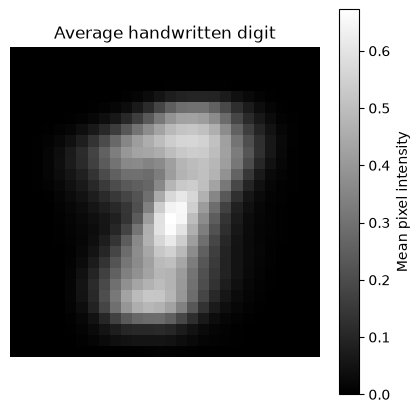

Overall mean pixel intensity: 0.1148


In [ ]:
# Digits dataset
mean_digits = np.mean(x2, axis=0)
mean_image = mean_digits.reshape(28, 28)

plt.figure(figsize=(5, 5))
plt.imshow(mean_image, cmap="gray")
plt.title("Average handwritten digit")
plt.colorbar(label="Mean pixel intensity")
plt.axis("off")
plt.show()

print(f"Overall mean pixel intensity: {x2.mean():.4f}")

The average image is blurry because it combines handwritten digits from three different classes. \
Most pixels are dark, which explains the low average pixel intensity.

## Predicting Diabetes on the Pima Dataset

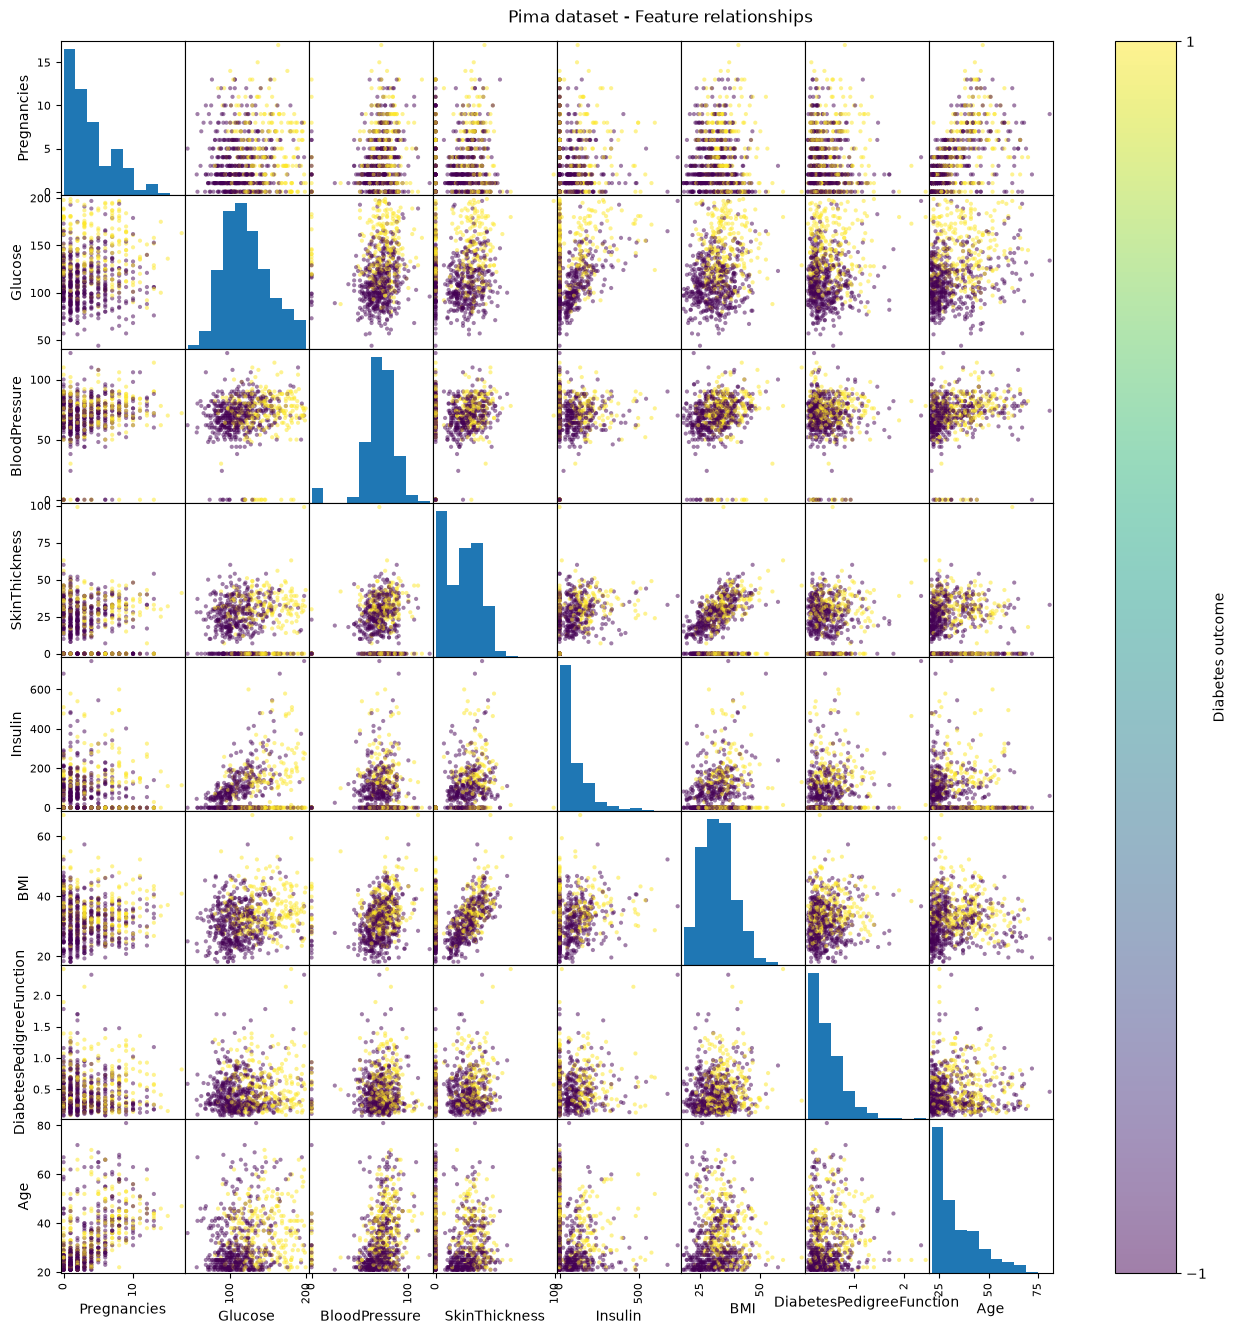

In [ ]:
df = pd.DataFrame(x1, columns=varnames)

axes = scatter_matrix(df, figsize=(16, 16), c=y1)
fig = plt.gcf()
fig.colorbar(axes[0, 1].collections[0], ax=axes.ravel().tolist(), ticks=[-1, 1], label="Diabetes outcome")
plt.suptitle("Pima dataset - Feature relationships", y=0.9)
plt.show()

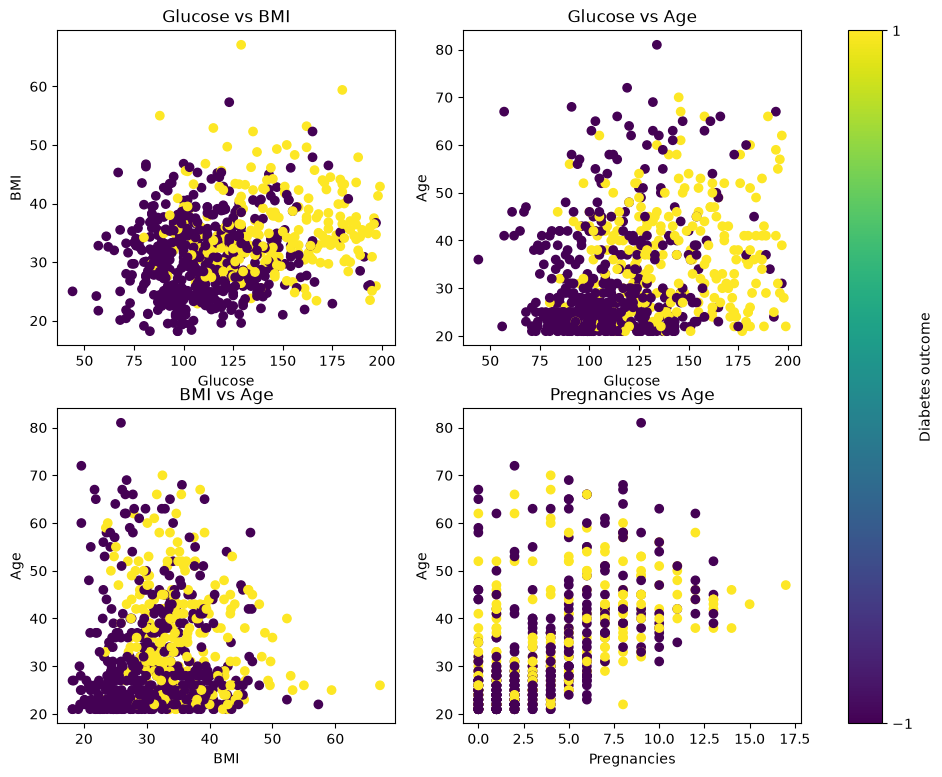

In [ ]:
pairs = [(1, 5), (1, 7), (5, 7), (0, 7)]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (i, j) in zip(axes.flat, pairs):
    scatter = ax.scatter(x1[:, i], x1[:, j], c=y1)

    ax.set_xlabel(varnames[i])
    ax.set_ylabel(varnames[j])
    ax.set_title(f"{varnames[i]} vs {varnames[j]}")

fig.colorbar(scatter, ax=axes.ravel().tolist(), ticks=[-1, 1], label="Diabetes outcome",)

plt.show()

Glucose appears to be the most informative feature, followed by BMI and age. \
Higher values are generally associated with diabetes, which makes sense medically. \
However, the two classes overlap significantly. \
Several features also contain unrealistic zero values, which may represent missing data.

In [ ]:
zero_count = np.sum(x1 == 0, axis=0)

for name, total in zip(varnames, zero_count):
    if total > 0:
        print(f"{name} : {total} zeros")

Pregnancies : 106 zeros
BloodPressure : 26 zeros
SkinThickness : 203 zeros
Insulin : 337 zeros


In [ ]:
n = 300

x_train = x1[:n]
x_test = x1[n:]

y_train = y1[:n]
y_test = y1[n:]

print("Train:", x_train.shape, y_train.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (300, 8) (300,)
Test: (409, 8) (409,)


In [ ]:
for name, std in zip(varnames, x_train.std(axis=0)):
    print(f"{name}: {std:.2f}")

Pregnancies: 3.32
Glucose: 30.02
BloodPressure: 17.89
SkinThickness: 15.65
Insulin: 116.10
BMI: 7.29
DiabetesPedigreeFunction: 0.33
Age: 10.85


The features have very different scales and variances. \
This can affect scale-sensitive models such as SVM and regularized classifiers.

In [ ]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

print("Train means:", np.round(x_train_scaled.mean(axis=0), 2))
print("Train std:", np.round(x_train_scaled.std(axis=0), 2))

Train means: [ 0.  0. -0.  0. -0.  0.  0.  0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
lda = LinearDiscriminantAnalysis()
lda.fit(x_train_scaled, y_train)

y_pred = lda.predict(x_test_scaled)
y_score = lda.predict_proba(x_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_score)

print(f"Accuracy: {acc:.4f}")
print(f"AUC: {auc:.4f}")

Accuracy: 0.7946
AUC: 0.8637


LDA achieves an accuracy of 79.46% and an AUC of 0.864. \
This suggests that a linear classifier can already distinguish the two classes reasonably well, despite their overlap.

In [ ]:
model = make_pipeline(
    StandardScaler(),
    LinearDiscriminantAnalysis(solver="lsqr")
)

param_grid = {
    "lineardiscriminantanalysis__shrinkage":
    [None, "auto"] + list(np.linspace(0, 1, 11))
}

grid = GridSearchCV(model, param_grid, cv=5, scoring="roc_auc")

grid.fit(x_train, y_train)

print("Best shrinkage:", grid.best_params_)
print(f"Best CV AUC: {grid.best_score_:.4f}")

lda_best = grid.best_estimator_

y_pred_best = lda_best.predict(x_test)
y_score_best = lda_best.predict_proba(x_test)[:, 1]

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Test AUC: {roc_auc_score(y_test, y_score_best):.4f}")

Best shrinkage: {'lineardiscriminantanalysis__shrinkage': np.float64(0.5)}
Best CV AUC: 0.8043
Test Accuracy: 0.8142
Test AUC: 0.8698


The best shrinkage value is 0.5, with a cross-validation AUC of 0.8043. \
Regularization slightly improves test accuracy from 79.46% to 81.42% and AUC from 0.8637 to 0.8698.

In [ ]:
qda = QuadraticDiscriminantAnalysis()
qda.fit(x_train_scaled, y_train)

y_pred_qda = qda.predict(x_test_scaled)
y_score_qda = qda.predict_proba(x_test_scaled)[:, 1]

acc_qda = accuracy_score(y_test, y_pred_qda)
auc_qda = roc_auc_score(y_test, y_score_qda)

print(f"QDA Accuracy: {acc_qda:.4f}")
print(f"QDA AUC: {auc_qda:.4f}")

QDA Accuracy: 0.7604
QDA AUC: 0.8109


QDA performs worse than LDA, with an accuracy of 76.04% and an AUC of 0.811.\
Its greater flexibility does not seem beneficial here, possibly because the training dataset is relatively small.

In [ ]:
model_qda = make_pipeline(
    StandardScaler(),
    QuadraticDiscriminantAnalysis()
)

param_grid_qda = {
    "quadraticdiscriminantanalysis__reg_param": np.linspace(0, 1, 21)
}

grid_qda = GridSearchCV(model_qda, param_grid_qda, cv=5, scoring="roc_auc")

grid_qda.fit(x_train, y_train)

print("Best reg_param:", grid_qda.best_params_)
print(f"Best CV AUC: {grid_qda.best_score_:.4f}")

qda_best = grid_qda.best_estimator_

y_pred_qda_best = qda_best.predict(x_test)
y_score_qda_best = qda_best.predict_proba(x_test)[:, 1]

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_qda_best):.4f}")
print(f"Test AUC: {roc_auc_score(y_test, y_score_qda_best):.4f}")

Best reg_param: {'quadraticdiscriminantanalysis__reg_param': np.float64(0.9)}
Best CV AUC: 0.8033
Test Accuracy: 0.7922
Test AUC: 0.8605


The best reg_param is 0.9, with a cross-validation AUC of 0.8033. \
Regularization improves QDA accuracy from 76.04% to 79.22% and AUC from 0.8109 to 0.8605. \
However, LDA still performs slightly better.

In [ ]:
gnb = GaussianNB()
gnb.fit(x_train_scaled, y_train)

y_pred_gnb = gnb.predict(x_test_scaled)
y_score_gnb = gnb.predict_proba(x_test_scaled)[:, 1]

acc_gnb = accuracy_score(y_test, y_pred_gnb)
auc_gnb = roc_auc_score(y_test, y_score_gnb)

print(f"Gaussian NB Accuracy: {acc_gnb:.4f}")
print(f"Gaussian NB AUC: {auc_gnb:.4f}")

Gaussian NB Accuracy: 0.7677
Gaussian NB AUC: 0.8310


Gaussian Naive Bayes achieves an accuracy of 76.77% and an AUC of 0.831.\
It performs slightly better than default QDA but worse than LDA. \
Its assumption of conditional independence between features may limit its performance.

In [ ]:
lr = LogisticRegression()
lr.fit(x_train_scaled, y_train)

y_pred_lr = lr.predict(x_test_scaled)
y_score_lr = lr.predict_proba(x_test_scaled)[:, 1]

acc_lr = accuracy_score(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, y_score_lr)

print(f"Logistic Regression Accuracy: {acc_lr:.4f}")
print(f"Logistic Regression AUC: {auc_lr:.4f}")

Logistic Regression Accuracy: 0.7946
Logistic Regression AUC: 0.8648


Logistic Regression achieves an accuracy of 79.46% and an AUC of 0.8648, very close to default LDA. \
This suggests that a linear decision boundary is suitable for this dataset.

In [ ]:
model_lr_l1 = make_pipeline(
    StandardScaler(),
    LogisticRegression(l1_ratio=1.0, solver="liblinear")
)

param_grid_lr = {
    "logisticregression__C": np.logspace(-3, 3, 20)
}

grid_lr = GridSearchCV(model_lr_l1, param_grid_lr, cv=5, scoring="roc_auc")

grid_lr.fit(x_train, y_train)

lr_l1_best = grid_lr.best_estimator_

y_pred_lr_l1 = lr_l1_best.predict(x_test)
y_score_lr_l1 = lr_l1_best.predict_proba(x_test)[:, 1]

print("Best C:", grid_lr.best_params_)
print(f"Best CV AUC: {grid_lr.best_score_:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_lr_l1):.4f}")
print(f"Test AUC: {roc_auc_score(y_test, y_score_lr_l1):.4f}")

Best C: {'logisticregression__C': np.float64(0.07847599703514611)}
Best CV AUC: 0.8084
Test Accuracy: 0.7946
Test AUC: 0.8691


The best C value is 0.0785, with a cross-validation AUC of 0.8084. \
L1 regularization slightly improves test AUC from 0.8648 to 0.8691, while accuracy remains unchanged at 79.46%.

In [ ]:
coef = lr_l1_best.named_steps["logisticregression"].coef_[0]

removed = np.isclose(coef, 0, atol=1e-8)

print(f"Selected features: {np.sum(~removed)}/{len(coef)}")
print("Removed features:", varnames[removed])

for name, weight in zip(varnames, coef):
    print(f"{name}: {weight:.4f}")

Selected features: 4/8
Removed features: ['BloodPressure' 'SkinThickness' 'Insulin' 'Age']
Pregnancies: 0.1928
Glucose: 0.6296
BloodPressure: 0.0000
SkinThickness: 0.0000
Insulin: 0.0000
BMI: 0.3533
DiabetesPedigreeFunction: 0.2029
Age: 0.0000


The L1-regularized model is sparse, keeping only 4 out of 8 features. \
Glucose has the largest positive coefficient, followed by BMI. \
BloodPressure, SkinThickness, Insulin and Age were removed. \
Despite using fewer features, the model maintains good predictive performance.

LDA gives the best results so far, with an accuracy of 81.42% and an AUC of 0.8698. \
Linear classifiers generally outperform the quadratic methods in this experiment, suggesting that a more complex decision boundary is not necessarily beneficial.

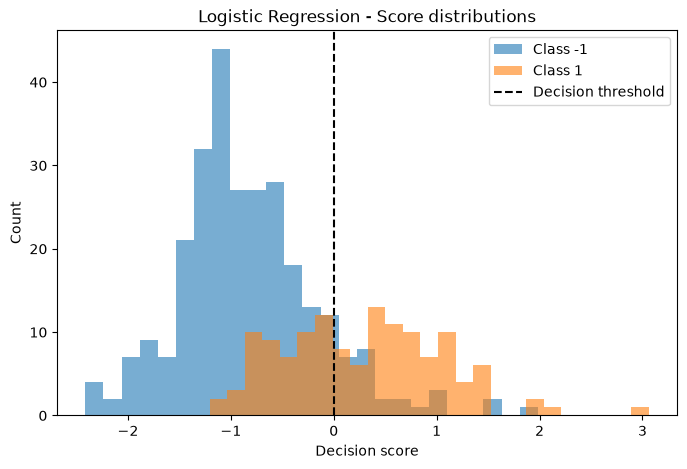

In [ ]:
scores = lr_l1_best.decision_function(x_test)

plt.figure(figsize=(8, 5))

for label in [-1, 1]:
    plt.hist(scores[y_test == label], alpha=0.6, label=f"Class {label}", bins=25)

plt.axvline(0, color="black", linestyle="--", label="Decision threshold")

plt.xlabel("Decision score")
plt.ylabel("Count")
plt.title("Logistic Regression - Score distributions")
plt.legend()
plt.show()

The decision scores show a clear tendency to separate the two classes.\
Non-diabetic patients mostly have negative scores, while diabetic patients tend to have higher scores. \
However, the distributions overlap, leading to both false positives and false negatives.

Glucose has the strongest positive coefficient, followed by BMI, DiabetesPedigreeFunction and Pregnancies. \
These associations are generally medically reasonable. \
The other features have zero coefficients due to L1 regularization, but this does not mean they are medically irrelevant.

In [ ]:
rf = RandomForestClassifier(random_state=42)
rf.fit(x_train, y_train)

y_pred_rf = rf.predict(x_test)
y_score_rf = rf.predict_proba(x_test)[:, 1]

acc_rf = accuracy_score(y_test, y_pred_rf)
auc_rf = roc_auc_score(y_test, y_score_rf)

print(f"Random Forest Accuracy: {acc_rf:.4f}")
print(f"Random Forest AUC: {auc_rf:.4f}")

Random Forest Accuracy: 0.7726
Random Forest AUC: 0.8495


Random Forest achieves an accuracy of 77.26% and an AUC of 0.8495. \
It performs worse than the optimized LDA, suggesting that a more complex nonlinear model does not necessarily improve generalization.

In [ ]:
param_grid_rf = {
    "n_estimators": [50, 100, 200, 500],
    "max_features": ["sqrt", "log2", 0.3, 0.5, 1.0]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_rf.fit(x_train, y_train)

rf_best = grid_rf.best_estimator_

y_pred_rf_best = rf_best.predict(x_test)
y_score_rf_best = rf_best.predict_proba(x_test)[:, 1]

print("Best parameters:", grid_rf.best_params_)
print(f"Best CV AUC: {grid_rf.best_score_:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_rf_best):.4f}")
print(f"Test AUC: {roc_auc_score(y_test, y_score_rf_best):.4f}")

Best parameters: {'max_features': 0.5, 'n_estimators': 50}
Best CV AUC: 0.7760
Test Accuracy: 0.7922
Test AUC: 0.8498


The best Random Forest uses 50 trees and max_features=0.5, with a cross-validation AUC of 0.7760. \
Test accuracy improves from 77.26% to 79.22%, while test AUC remains almost unchanged at 0.8498.

In [ ]:
svc = SVC()
svc.fit(x_train_scaled, y_train)

y_pred_svc = svc.predict(x_test_scaled)
y_score_svc = svc.decision_function(x_test_scaled)

acc_svc = accuracy_score(y_test, y_pred_svc)
auc_svc = roc_auc_score(y_test, y_score_svc)

print(f"SVC Accuracy: {acc_svc:.4f}")
print(f"SVC AUC: {auc_svc:.4f}")

SVC Accuracy: 0.7873
SVC AUC: 0.8385


SVC achieves an accuracy of 78.73% and an AUC of 0.8385. \
It performs slightly worse than the optimized Random Forest and LDA, suggesting that its default configuration is not optimal for this dataset.

In [ ]:
model_svc = make_pipeline(
    StandardScaler(),
    SVC()
)

param_grid_svc = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.01, 0.1, 1, "scale"]
}

grid_svc = GridSearchCV(
    model_svc,
    param_grid_svc,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_svc.fit(x_train, y_train)

svc_best = grid_svc.best_estimator_

y_pred_svc_best = svc_best.predict(x_test)
y_score_svc_best = svc_best.decision_function(x_test)

print("Best parameters:", grid_svc.best_params_)
print(f"Best CV AUC: {grid_svc.best_score_:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_svc_best):.4f}")
print(f"Test AUC: {roc_auc_score(y_test, y_score_svc_best):.4f}")

Best parameters: {'svc__C': 0.1, 'svc__gamma': 0.01}
Best CV AUC: 0.8026
Test Accuracy: 0.6773
Test AUC: 0.8626


The optimized SVC achieves an AUC of 0.8626 but a relatively low accuracy of 67.73%. \
This suggests that the model ranks the classes reasonably well, but its default decision threshold may not be appropriate.

In [ ]:
mlp = MLPClassifier(random_state=42, max_iter=2500)
mlp.fit(x_train_scaled, y_train)

y_pred_mlp = mlp.predict(x_test_scaled)
y_score_mlp = mlp.predict_proba(x_test_scaled)[:, 1]

acc_mlp = accuracy_score(y_test, y_pred_mlp)
auc_mlp = roc_auc_score(y_test, y_score_mlp)

print(f"MLP Accuracy: {acc_mlp:.4f}")
print(f"MLP AUC: {auc_mlp:.4f}")

MLP Accuracy: 0.7751
MLP AUC: 0.8113


The MLP achieves an accuracy of 77.51% and an AUC of 0.8113, performing worse than the optimized LDA.

In [ ]:
model_mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(max_iter=2500, random_state=42)
)

param_grid_mlp = {
    "mlpclassifier__hidden_layer_sizes": [
        (20,), (50,), (100,), (50, 25)
    ],
    "mlpclassifier__alpha": [
        0.0001, 0.01, 0.1, 1, 10, 100
    ]
}

grid_mlp = GridSearchCV(
    model_mlp,
    param_grid_mlp,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_mlp.fit(x_train, y_train)

mlp_best = grid_mlp.best_estimator_

y_pred_mlp_best = mlp_best.predict(x_test)
y_score_mlp_best = mlp_best.predict_proba(x_test)[:, 1]

print("Best parameters:", grid_mlp.best_params_)
print(f"Best CV AUC: {grid_mlp.best_score_:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_mlp_best):.4f}")
print(f"Test AUC: {roc_auc_score(y_test, y_score_mlp_best):.4f}")

Best parameters: {'mlpclassifier__alpha': 10, 'mlpclassifier__hidden_layer_sizes': (100,)}
Best CV AUC: 0.8053
Test Accuracy: 0.7995
Test AUC: 0.8681


The best MLP uses 100 hidden neurons and alpha=10. \
Regularization improves test accuracy from 77.51% to 79.95% and AUC from 0.8113 to 0.8681. \
Its performance is now very close to the optimized LDA.

In [ ]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(x_train, y_train)

y_pred_gb = gb.predict(x_test)
y_score_gb = gb.predict_proba(x_test)[:, 1]

acc_gb = accuracy_score(y_test, y_pred_gb)
auc_gb = roc_auc_score(y_test, y_score_gb)

print(f"Gradient Boosting Accuracy: {acc_gb:.4f}")
print(f"Gradient Boosting AUC: {auc_gb:.4f}")

Gradient Boosting Accuracy: 0.7555
Gradient Boosting AUC: 0.8292


Gradient Boosting achieves an accuracy of 75.55% and an AUC of 0.8292, performing worse than the optimized LDA and MLP.

In [ ]:
param_grid_gb = {
    "n_estimators": [50, 100, 200, 400],
    "learning_rate": [0.01, 0.05, 0.1, 0.2]
}

grid_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid_gb,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_gb.fit(x_train, y_train)

gb_best = grid_gb.best_estimator_

y_pred_gb_best = gb_best.predict(x_test)
y_score_gb_best = gb_best.predict_proba(x_test)[:, 1]

print("Best parameters:", grid_gb.best_params_)
print(f"Best CV AUC: {grid_gb.best_score_:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_gb_best):.4f}")
print(f"Test AUC: {roc_auc_score(y_test, y_score_gb_best):.4f}")

Best parameters: {'learning_rate': 0.05, 'n_estimators': 50}
Best CV AUC: 0.7646
Test Accuracy: 0.7775
Test AUC: 0.8429


The best Gradient Boosting model uses 50 estimators and a learning rate of 0.05, with a CV AUC of 0.7646. \
Test accuracy improves from 75.55% to 77.75%, and AUC increases from 0.8292 to 0.8429. \
However, it still performs worse than the optimized LDA.

In [ ]:
results = pd.DataFrame({
    "Model": [
        "LDA", "LDA optimized",
        "QDA", "QDA optimized",
        "Gaussian NB",
        "Logistic Regression", "Logistic Regression L1",
        "Random Forest", "Random Forest optimized",
        "SVC", "SVC optimized",
        "MLP", "MLP optimized",
        "Gradient Boosting", "Gradient Boosting optimized"
    ],
    "Accuracy": [
        0.7946, 0.8142,
        0.7604, 0.7922,
        0.7677,
        0.7946, 0.7946,
        0.7726, 0.7922,
        0.7873, 0.6773,
        0.7751, 0.7995,
        0.7555, 0.7775
    ],
    "AUC": [
        0.8637, 0.8698,
        0.8109, 0.8605,
        0.8310,
        0.8648, 0.8691,
        0.8495, 0.8498,
        0.8385, 0.8626,
        0.8113, 0.8681,
        0.8292, 0.8429
    ]
})

display(results.sort_values("AUC", ascending=False).round(4))

,Model,Accuracy,AUC
1,LDA optimized,0.8142,0.8698
6,Logistic Regression L1,0.7946,0.8691
12,MLP optimized,0.7995,0.8681
5,Logistic Regression,0.7946,0.8648
0,LDA,0.7946,0.8637
10,SVC optimized,0.6773,0.8626
3,QDA optimized,0.7922,0.8605
8,Random Forest optimized,0.7922,0.8498
7,Random Forest,0.7726,0.8495
14,Gradient Boosting optimized,0.7775,0.8429


Optimized LDA achieves the highest accuracy (81.42%) and AUC (0.8698), closely followed by Logistic Regression L1 and MLP. \
Nonlinear models do not outperform the best linear classifiers on this dataset. \
Simpler models seem sufficient for this classification task.

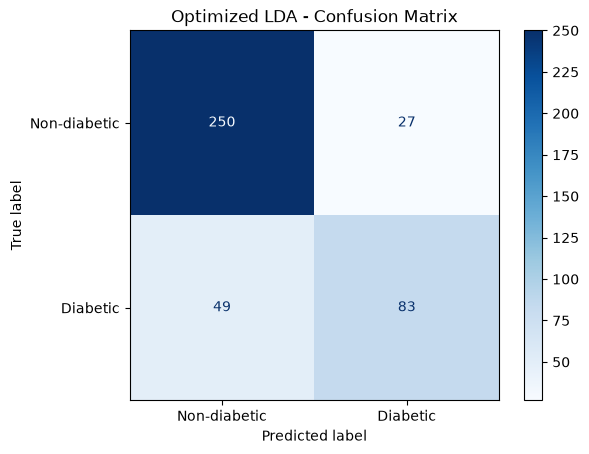

False Negative Rate: 37.12%


In [ ]:
y_pred = lda_best.predict(x_test)

cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-diabetic", "Diabetic"]
).plot(cmap="Blues")

plt.title("Optimized LDA - Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()
fnr = fn / (fn + tp)

print(f"False Negative Rate: {fnr:.2%}")

The optimized LDA has a false negative rate of 37.12%, meaning that 49 out of 132 diabetic patients are missed. \
Despite its good accuracy, this is a serious limitation for medical screening, where false negatives can have important consequences.

Selected threshold: 0.1582
New FNR: 4.55%
New Accuracy: 65.77%
False positives: 134
False negatives: 6


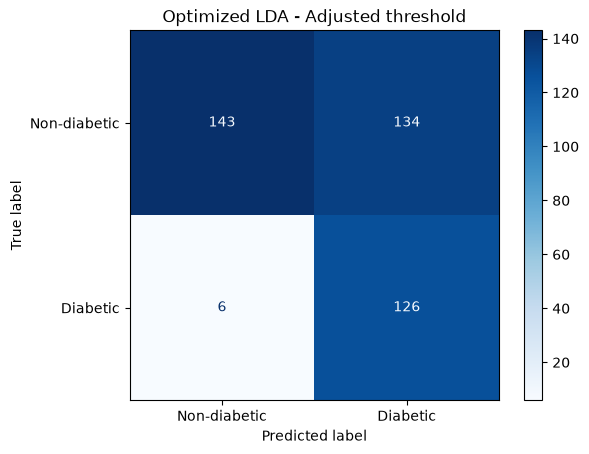

In [ ]:
cv_proba = cross_val_predict(
    clone(lda_best),
    x_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

thresholds = np.unique(cv_proba)

fnr_values = [
    np.mean(cv_proba[y_train == 1] < t)
    for t in thresholds
]

valid_thresholds = thresholds[np.array(fnr_values) < 0.10]
best_threshold = valid_thresholds.max()

print(f"Selected threshold: {best_threshold:.4f}")

test_proba = lda_best.predict_proba(x_test)[:, 1]
y_pred_new = np.where(test_proba >= best_threshold, 1, -1)

cm_new = confusion_matrix(y_test, y_pred_new, labels=[-1, 1])

tn, fp, fn, tp = cm_new.ravel()

print(f"New FNR: {fn / (fn + tp):.2%}")
print(f"New Accuracy: {accuracy_score(y_test, y_pred_new):.2%}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")

ConfusionMatrixDisplay(
    confusion_matrix=cm_new,
    display_labels=["Non-diabetic", "Diabetic"]
).plot(cmap="Blues")

plt.title("Optimized LDA - Adjusted threshold")
plt.show()

Lowering the decision threshold to 0.1582 reduces the FNR from 37.12% to 4.55%, allowing the model to detect 126 out of 132 diabetic patients.\
However, false positives increase from 27 to 134, reducing accuracy to 65.77%.\
This trade-off may be acceptable for medical screening, where missing diabetic patients can be particularly harmful.

## Predicting Classes on the Digits dataset

In [ ]:
lda_digits = LinearDiscriminantAnalysis()
lda_digits.fit(x2, y2)

y_pred_digits = lda_digits.predict(xt2)

acc_lda_digits = accuracy_score(yt2, y_pred_digits)

print(f"LDA Accuracy: {acc_lda_digits:.4f}")

LDA Accuracy: 0.9333


LDA achieves a test accuracy of 93.33%, showing that a linear classifier can already distinguish the three handwritten digits quite well.

In [ ]:
param_grid_lda_digits = {
    "shrinkage": [None, 0.05, 0.2, 0.5, "auto"]
}

grid_lda_digits = GridSearchCV(
    LinearDiscriminantAnalysis(solver="lsqr"),
    param_grid_lda_digits,
    cv=5,
    scoring="accuracy"
)

grid_lda_digits.fit(x2, y2)

lda_digits_best = grid_lda_digits.best_estimator_

acc_lda_digits_best = accuracy_score(yt2, lda_digits_best.predict(xt2))

print("Best parameters:", grid_lda_digits.best_params_)
print(f"Best CV Accuracy: {grid_lda_digits.best_score_:.4f}")
print(f"Test Accuracy: {acc_lda_digits_best:.4f}")

Best parameters: {'shrinkage': 0.2}
Best CV Accuracy: 0.9570
Test Accuracy: 0.9473


The best shrinkage value is 0.2, with a cross-validation accuracy of 95.70%. \
Regularization improves test accuracy from 93.33% to 94.73%, suggesting that it helps stabilize covariance estimation.

In [ ]:
lr_digits = LogisticRegression()
lr_digits.fit(x2, y2)

y_pred_lr_digits = lr_digits.predict(xt2)

acc_lr_digits = accuracy_score(yt2, y_pred_lr_digits)

print(f"Logistic Regression Accuracy: {acc_lr_digits:.4f}")

Logistic Regression Accuracy: 0.9647


Logistic Regression achieves an accuracy of 96.47%, outperforming the optimized LDA.\
This shows that a linear discriminative classifier works very well for recognizing these three digits.

In [ ]:
param_grid_lr_digits = {
    "C": np.logspace(-3, 2, 8)
}

grid_lr_digits = GridSearchCV(
    LogisticRegression(),
    param_grid_lr_digits,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_lr_digits.fit(x2, y2)

lr_digits_best = grid_lr_digits.best_estimator_

acc_lr_digits_best = accuracy_score(yt2, lr_digits_best.predict(xt2))

print("Best parameters:", grid_lr_digits.best_params_)
print(f"Best CV Accuracy: {grid_lr_digits.best_score_:.4f}")
print(f"Test Accuracy: {acc_lr_digits_best:.4f}")

Best parameters: {'C': np.float64(0.13894954943731375)}
Best CV Accuracy: 0.9770
Test Accuracy: 0.9673


The best C value is 0.1389, with a cross-validation accuracy of 97.70%. \
Regularization slightly improves test accuracy from 96.47% to 96.73%, making Logistic Regression the best classifier so far.

In [ ]:
svc_digits = SVC()
svc_digits.fit(x2, y2)

y_pred_svc_digits = svc_digits.predict(xt2)

acc_svc_digits = accuracy_score(yt2, y_pred_svc_digits)

print(f"SVC Accuracy: {acc_svc_digits:.4f}")

SVC Accuracy: 0.9833


SVC achieves a test accuracy of 98.33%, outperforming both LDA and Logistic Regression.\
Its nonlinear RBF kernel seems well suited to recognizing handwritten digits.

In [ ]:
param_grid_svc_digits = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, "scale"]
}

grid_svc_digits = GridSearchCV(
    SVC(),
    param_grid_svc_digits,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_svc_digits.fit(x2, y2)

svc_digits_best = grid_svc_digits.best_estimator_

acc_svc_digits_best = accuracy_score(yt2, svc_digits_best.predict(xt2))

print("Best parameters:", grid_svc_digits.best_params_)
print(f"Best CV Accuracy: {grid_svc_digits.best_score_:.4f}")
print(f"Test Accuracy: {acc_svc_digits_best:.4f}")

Best parameters: {'C': 10, 'gamma': 'scale'}
Best CV Accuracy: 0.9910
Test Accuracy: 0.9833


The best SVC uses C=10 and gamma="scale", with a cross-validation accuracy of 99.10%.\
However, test accuracy remains unchanged at 98.33%, so tuning does not provide a measurable improvement on the test set.

In [ ]:
mlp_digits = MLPClassifier(random_state=42)

mlp_digits.fit(x2, y2)

y_pred_mlp_digits = mlp_digits.predict(xt2)
acc_mlp_digits = accuracy_score(yt2, y_pred_mlp_digits)

print(f"MLP Accuracy: {acc_mlp_digits:.4f}")
print(f"Iterations used: {mlp_digits.n_iter_}")

MLP Accuracy: 0.9827
Iterations used: 60


The MLP achieves an accuracy of 98.27%, almost identical to SVC.

In [ ]:
param_grid_mlp_digits = {
    "hidden_layer_sizes": [(50,), (100,), (100, 50)],
    "alpha": [0.0001, 0.01, 0.1, 1]
}

grid_mlp_digits = GridSearchCV(
    MLPClassifier(random_state=42),
    param_grid_mlp_digits,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_mlp_digits.fit(x2, y2)

mlp_digits_best = grid_mlp_digits.best_estimator_

acc_mlp_digits_best = accuracy_score(yt2, mlp_digits_best.predict(xt2))

print("Best parameters:", grid_mlp_digits.best_params_)
print(f"Best CV Accuracy: {grid_mlp_digits.best_score_:.4f}")
print(f"Test Accuracy: {acc_mlp_digits_best:.4f}")
print(f"Iterations used: {mlp_digits_best.n_iter_}")

Best parameters: {'alpha': 0.0001, 'hidden_layer_sizes': (100, 50)}
Best CV Accuracy: 0.9863
Test Accuracy: 0.9813
Iterations used: 42


The best MLP configuration uses two hidden layers (100, 50) and alpha=0.0001, with a CV accuracy of 98.63%.\
However, test accuracy slightly decreases from 98.27% to 98.13%, so the additional layer does not improve performance on the test set.

In [ ]:
models_digits = {
    "LDA": lda_digits_best,
    "Logistic Regression": lr_digits_best,
    "SVC": svc_digits_best,
    "MLP": mlp_digits_best
}

results_digits = []

for name, model in models_digits.items():
    y_pred = model.predict(xt2)

    results_digits.append({
        "Model": name,
        "Accuracy": accuracy_score(yt2, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(yt2, y_pred),
        "Macro F1": f1_score(yt2, y_pred, average="macro")
    })

df_results_digits = pd.DataFrame(results_digits)

display(df_results_digits.sort_values("Accuracy", ascending=False).round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1
2,SVC,0.9833,0.9833,0.9833
3,MLP,0.9813,0.9813,0.9813
1,Logistic Regression,0.9673,0.9673,0.9673
0,LDA,0.9473,0.9473,0.9475


SVC achieves the best performance with an accuracy and macro F1-score of 98.33%, closely followed by MLP. \
The three metrics are very similar because the dataset is balanced across the three classes.

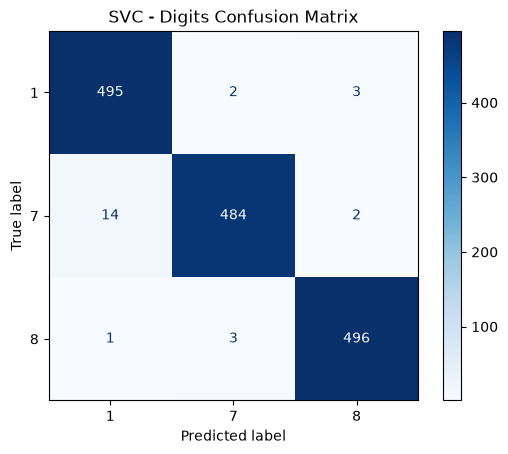

              precision    recall  f1-score   support

           1       0.97      0.99      0.98       500
           7       0.99      0.97      0.98       500
           8       0.99      0.99      0.99       500

    accuracy                           0.98      1500
   macro avg       0.98      0.98      0.98      1500
weighted avg       0.98      0.98      0.98      1500



In [ ]:
y_pred_digits_best = svc_digits_best.predict(xt2)

cm_digits = confusion_matrix(yt2, y_pred_digits_best, labels=[1, 7, 8])

ConfusionMatrixDisplay(confusion_matrix=cm_digits, display_labels=[1, 7, 8]).plot(cmap="Blues")

plt.title("SVC - Digits Confusion Matrix")
plt.show()

print(classification_report(yt2, y_pred_digits_best))

The digit 7 is the hardest to recognize, with 16 misclassified samples, including 14 predicted as 1.\
This may be due to similarities between handwritten 1s and 7s. \
Digit 8 has the highest recall, with only 4 errors.

Number of errors: 25


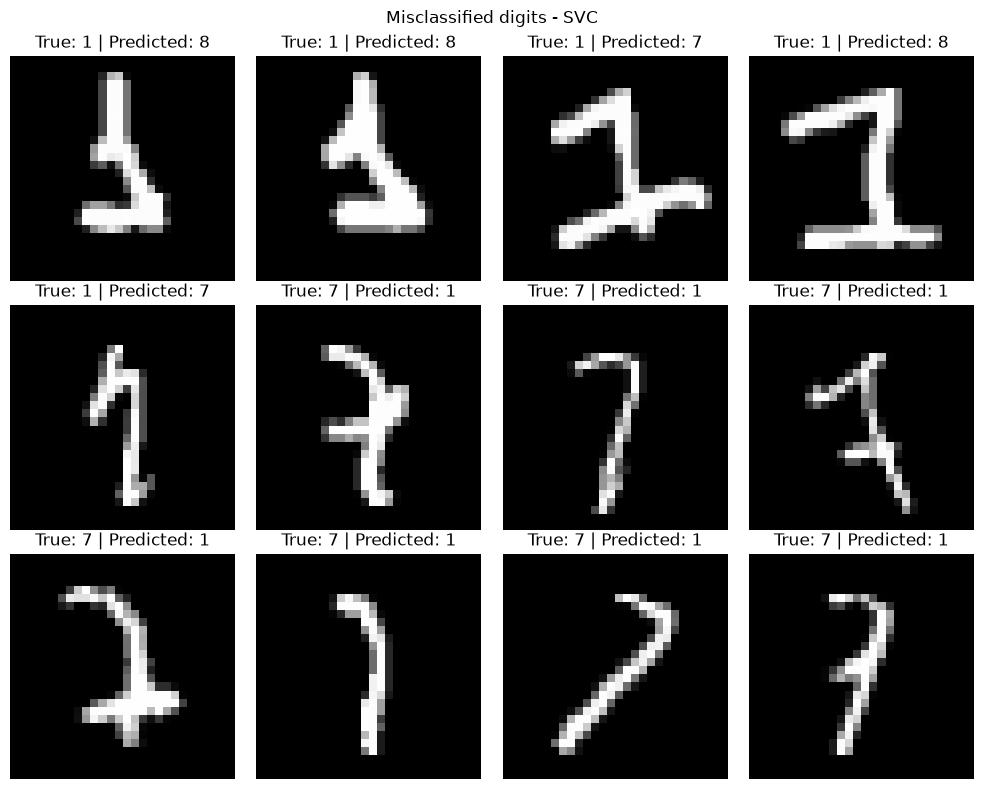

In [ ]:
wrong_idx = np.where(y_pred_digits_best != yt2)[0]

print(f"Number of errors: {len(wrong_idx)}")

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, idx in zip(axes.flat, wrong_idx[:12]):
    image = xt2[idx].reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"True: {yt2[idx]} | Predicted: {y_pred_digits_best[idx]}")
    ax.axis("off")

plt.suptitle("Misclassified digits - SVC")
plt.tight_layout()
plt.show()

Most misclassified digits have unusual or ambiguous handwriting. \
Several 7s resemble 1s because of their short or unclear horizontal strokes. \
Some 1s also contain additional strokes that confuse the classifier. \
These examples help explain the 25 classification errors.

In [ ]:
idx = np.where((yt2 == 7) & (y_pred_digits_best == yt2))[0][0]

original = xt2[idx]
true_label = yt2[idx]

np.random.seed(42)
noise_std = 0.25

noisy_samples = original + noise_std * np.random.randn(1000, 784)
noisy_samples = np.clip(noisy_samples, 0, 1)

noisy_pred = svc_digits_best.predict(noisy_samples)
accuracy_noisy = np.mean(noisy_pred == yt2[idx])

print(f"Noisy accuracy: {accuracy_noisy:.4f}")

Noisy accuracy: 1.0000


In [ ]:
# Increase Gaussian noise
np.random.seed(42)
noise_std = 0.35

noisy_samples = original + noise_std * np.random.randn(1000, 784)
noisy_samples = np.clip(noisy_samples, 0, 1)

noisy_pred = svc_digits_best.predict(noisy_samples)
accuracy_noisy = np.mean(noisy_pred == true_label)

print(f"Noisy accuracy: {accuracy_noisy:.4f}")

Noisy accuracy: 1.0000


In [ ]:
# Increase Gaussian noise
np.random.seed(42)
noise_std = 0.45

noisy_samples = original + noise_std * np.random.randn(1000, 784)
noisy_samples = np.clip(noisy_samples, 0, 1)

noisy_pred = svc_digits_best.predict(noisy_samples)
accuracy_noisy = np.mean(noisy_pred == true_label)

print(f"Noisy accuracy: {accuracy_noisy:.4f}")

Noisy accuracy: 0.9530


Misclassified samples: 47/1000


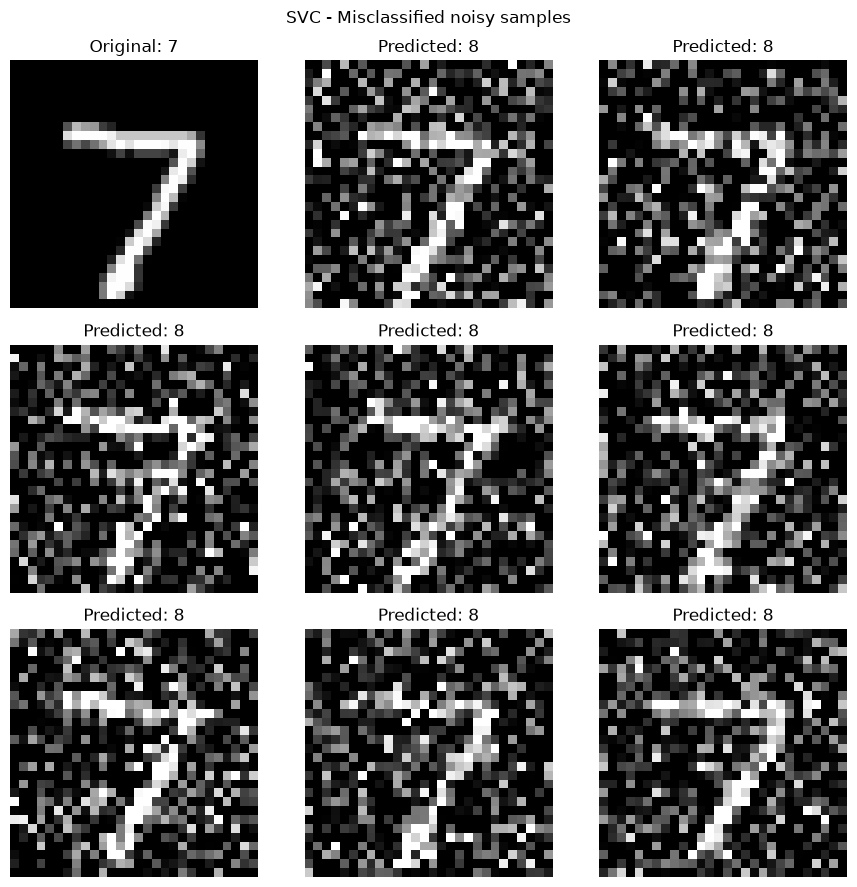

In [ ]:
wrong_idx = np.where(noisy_pred != true_label)[0]

print(f"Misclassified samples: {len(wrong_idx)}/1000")

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

axes.flat[0].imshow(original.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
axes.flat[0].set_title(f"Original: {true_label}")

for ax, idx in zip(axes.flat[1:], wrong_idx[:8]):
    ax.imshow(noisy_samples[idx].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Predicted: {noisy_pred[idx]}")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("SVC - Misclassified noisy samples")
plt.tight_layout()
plt.show()

The SVC correctly classifies all 1000 samples with noise levels of 0.25 and 0.35. \
At 0.45, accuracy drops to 95.30%, with 47 errors. \
The misclassified images are mostly still recognizable as 7s, but the added noise makes the classifier predict 8. \
This shows that the SVC is reasonably robust to Gaussian noise on this sample, although its predictions become less reliable with stronger perturbations.

## Bonus: Convolutional Neural network (CNN)

In [ ]:
# DataLoader
torch.manual_seed(42)

X_digits = torch.tensor(x2.reshape(-1, 1, 28, 28), dtype=torch.float32)

classes = np.array([1, 7, 8])
y_digits = torch.tensor(np.searchsorted(classes, y2), dtype=torch.long)

train_idx, val_idx = train_test_split(
    np.arange(len(y2)),
    test_size=0.2,
    stratify=y2,
    random_state=42
)

train_loader = DataLoader(
    TensorDataset(X_digits[train_idx], y_digits[train_idx]),
    batch_size=64,
    shuffle=True
)

print("Images:", X_digits.shape)
print("Labels:", y_digits.shape)

Images: torch.Size([3000, 1, 28, 28])
Labels: torch.Size([3000])


In [ ]:
# Model
cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64),
    nn.ReLU(),
    nn.Linear(64, 3)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn = cnn.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)

print("Device:", device)

Device: cpu


In [ ]:
# Train CNN
epochs = 10

for epoch in range(epochs):
    cnn.train()

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = cnn(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

    cnn.eval()
    with torch.no_grad():
        logits_val = cnn(X_digits[val_idx].to(device))
        pred_val = logits_val.argmax(dim=1).cpu()
        val_acc = (pred_val == y_digits[val_idx]).float().mean().item()

    print(f"Epoch {epoch+1}: Validation Accuracy = {val_acc:.4f}")

Epoch 1: Validation Accuracy = 0.9500
Epoch 2: Validation Accuracy = 0.9667
Epoch 3: Validation Accuracy = 0.9817
Epoch 4: Validation Accuracy = 0.9833
Epoch 5: Validation Accuracy = 0.9833
Epoch 6: Validation Accuracy = 0.9800
Epoch 7: Validation Accuracy = 0.9850
Epoch 8: Validation Accuracy = 0.9850
Epoch 9: Validation Accuracy = 0.9917
Epoch 10: Validation Accuracy = 0.9917


The CNN reaches 99.17% validation accuracy after 10 epochs.\
Performance improves quickly during training, with only small fluctuations. \
This suggests that the CNN learns useful spatial features from the handwritten digits.

In [ ]:
# Configure and compare number of filters
def train_cnn(filters, learning_rate=0.001, epochs=10):
    torch.manual_seed(42)
    f1, f2 = filters

    model = nn.Sequential(
        nn.Conv2d(1, f1, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(f1, f2, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Flatten(),
        nn.Linear(f2 * 7 * 7, 64),
        nn.ReLU(),
        nn.Linear(64, 3)
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()

    loader = DataLoader(
        TensorDataset(X_digits[train_idx], y_digits[train_idx]),
        batch_size=64,
        shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )

    best_acc = 0

    for epoch in range(epochs):
        model.train()

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            pred = model(X_digits[val_idx].to(device)).argmax(dim=1).cpu()
            acc = (pred == y_digits[val_idx]).float().mean().item()

        best_acc = max(best_acc, acc)

    return best_acc

In [ ]:
# Compare filters
for filters in [(8, 16), (16, 32), (32, 64)]:
    acc = train_cnn(filters)

    print(f"Filters {filters}: Best Validation Accuracy = {acc:.4f}")

Filters (8, 16): Best Validation Accuracy = 0.9917
Filters (16, 32): Best Validation Accuracy = 0.9900
Filters (32, 64): Best Validation Accuracy = 0.9933


The CNN with (32, 64) filters achieves the highest validation accuracy of 99.33%.\
However, the differences between architectures are very small, suggesting that increasing the number of filters provides only a limited benefit.

In [ ]:
# Compare learning rates
learning_rates = [0.0001, 0.0003, 0.001, 0.003]

for lr in learning_rates:
    acc = train_cnn(filters=(32, 64), learning_rate=lr, epochs=10)

    print(f"Learning rate {lr}: Best Validation Accuracy = {acc:.4f}")

Learning rate 0.0001: Best Validation Accuracy = 0.9800
Learning rate 0.0003: Best Validation Accuracy = 0.9867
Learning rate 0.001: Best Validation Accuracy = 0.9933
Learning rate 0.003: Best Validation Accuracy = 0.9933


Learning rates of 0.001 and 0.003 achieve the highest validation accuracy of 99.33%. \
Smaller learning rates perform worse after 10 epochs, suggesting slower convergence.\
We select 0.001 for the final CNN.

In [ ]:
# Build final CNN on full training set
torch.manual_seed(42)

cnn_final = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 64),
    nn.ReLU(),
    nn.Linear(64, 3)
).to(device)

train_loader_full = DataLoader(
    TensorDataset(X_digits, y_digits),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_final.parameters(), lr=0.001)

for epoch in range(10):
    cnn_final.train()
    total_loss = 0

    for xb, yb in train_loader_full:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        loss = criterion(cnn_final(xb), yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    print(f"Epoch {epoch+1}: Loss = {total_loss / len(X_digits):.4f}")

Epoch 1: Loss = 0.3788
Epoch 2: Loss = 0.0880
Epoch 3: Loss = 0.0522
Epoch 4: Loss = 0.0387
Epoch 5: Loss = 0.0387
Epoch 6: Loss = 0.0238
Epoch 7: Loss = 0.0205
Epoch 8: Loss = 0.0139
Epoch 9: Loss = 0.0137
Epoch 10: Loss = 0.0098


In [ ]:
# Validate on test set
X_test_digits = torch.tensor(xt2.reshape(-1, 1, 28, 28), dtype=torch.float32)

test_loader = DataLoader(
    X_test_digits,
    batch_size=128,
    shuffle=False
)

cnn_final.eval()
predictions = []

with torch.no_grad():
    for xb in test_loader:
        logits = cnn_final(xb.to(device))
        predictions.append(logits.argmax(dim=1).cpu())

pred_indices = torch.cat(predictions).numpy()
y_pred_cnn_digits = classes[pred_indices]

acc_cnn_digits = accuracy_score(yt2, y_pred_cnn_digits)

print(f"CNN Test Accuracy: {acc_cnn_digits:.4f}")
print(f"SVC Test Accuracy: {acc_svc_digits_best:.4f}")

CNN Test Accuracy: 0.9893
SVC Test Accuracy: 0.9833


The CNN achieves 98.93% test accuracy, outperforming SVC at 98.33%. \
Training loss decreases steadily from 0.3788 to 0.0098. \
This suggests that convolutional layers are effective at learning spatial features from handwritten digits.

In [ ]:
# Compare robustness to noise
idx = np.where((yt2 == 7) & (y_pred_digits_best == 7) & (y_pred_cnn_digits == 7))[0][0]

original = xt2[idx]
true_label = yt2[idx]

np.random.seed(42)
noise = np.random.randn(1000, 784)

noise_levels = [0.25, 0.35, 0.45]
results_noise = []

cnn_final.eval()

for noise_std in noise_levels:
    noisy_samples = np.clip(original + noise_std * noise, 0, 1)

    svc_pred = svc_digits_best.predict(noisy_samples)
    svc_acc = np.mean(svc_pred == true_label)

    noisy_tensor = torch.tensor(noisy_samples.reshape(-1, 1, 28, 28), dtype=torch.float32)

    predictions = []

    with torch.no_grad():
        for xb in torch.split(noisy_tensor, 128):
            logits = cnn_final(xb.to(device))
            predictions.append(logits.argmax(dim=1).cpu())

    cnn_pred = classes[torch.cat(predictions).numpy()]
    cnn_acc = np.mean(cnn_pred == true_label)

    results_noise.append({
        "Noise std": noise_std,
        "SVC Accuracy": svc_acc,
        "CNN Accuracy": cnn_acc
    })

display(pd.DataFrame(results_noise).round(4))

,Noise std,SVC Accuracy,CNN Accuracy
0,0.25,1.000,1.000
1,0.35,1.000,0.999
2,0.45,0.953,0.981


The CNN achieves 98.93% test accuracy, compared to 98.33% for the SVC. \
Both models are highly robust to low levels of Gaussian noise.\
At a noise level of 0.45, the CNN maintains 98.1% accuracy, while the SVC drops to 95.3%.

These results suggest that the CNN is more robust to strong Gaussian noise on the selected image.\
However, further experiments on different digits would be needed to confirm this conclusion.

## Personal discussion

This practical work helped me better understand how to interpret evaluation metrics such as accuracy and AUC, and why distinguishing false positives from false negatives is important in real-world applications, especially in medical diagnosis.

I also discovered how to evaluate a model's robustness by adding noise to the input data.

My main difficulty was understanding how to organize data preprocessing, cross-validation, training, and hyperparameter tuning in the correct order to avoid data leakage. \
This helped me understand the importance of a rigorous evaluation process when building machine learning models.

Next time, I would define the evaluation metrics in advance and use pipelines more systematically to avoid data leakage.

In a professional setting, I would pay particular attention to the consequences of different types of errors, rather than relying only on accuracy.